In [ ]:
# 整理后的R包加载与配置

# 基础分析包
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(dplyr))
suppressMessages(library(ggplot2))
suppressMessages(library(future))
suppressMessages(library(parallel))
suppressMessages(library(Nebulosa))
suppressMessages(library(RColorBrewer))
suppressMessages(library(viridis))
suppressMessages(library(qs))

# 多组学/转录因子包
suppressMessages(library(scMEGA))
suppressMessages(library(Pando))
suppressMessages(library(harmony))

# motif 分析等
# suppressMessages(library(JASPAR2020))
suppressMessages(library(TFBSTools))
suppressMessages(library(chromVAR))
suppressMessages(library(motifmatchr))

# 可视化
suppressMessages(library(igraph))
suppressMessages(library(ggraph))

# 基因组分析
# suppressMessages(library(BSgenome.Hsapiens.UCSC.hg38))
suppressMessages(library(GenomicRanges))
suppressMessages(library(BSgenome))
suppressMessages(library(Rsamtools))  # FaFile
suppressMessages(library(ChIPseeker))
suppressMessages(library(GenomicFeatures))
suppressMessages(library(rtracklayer)) # 读写 BED/GFF
suppressMessages(library(txdbmaker))
library(enrichR)

# Python 环境
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/betz_snRNA_snATAC/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/betz_snRNA_snATAC/.venv")

# 资源设定
plan("multicore", workers = 64)
options(future.globals.maxSize = 100000 * 1024^5)

# 加载 genome 注释
load('/home/chaiqw/project/macaque_motor_new/macFas5_genomeInfo_signac.RData')

# 网络代理设定
Sys.setenv(
  http_proxy  = "http://10.10.50.114:45698",
  https_proxy = "http://10.10.50.114:45698"
)


In [2]:
sub_rna = readRDS('M1_data_sub_4.rds')
sub_rna

An object of class Seurat 
23306 features across 3713 samples within 1 assay 
Active assay: RNA (23306 features, 5000 variable features)
 3 layers present: data, counts, scale.data
 3 dimensional reductions calculated: pca, harmony, umap

In [3]:
# 合并 L5-ET(PT).02(Betz-Like) 和 L5-ET(PT).00 为 celltype_new
sub_rna$celltype_new <- as.character(sub_rna$celltype)
sub_rna$celltype_new[sub_rna$celltype_new %in% c("L5-ET(PT).02(Betz-Like)", "L5-ET(PT).00")] <- "Betz Like"
sub_rna$celltype_new <- as.factor(sub_rna$celltype_new)


In [4]:
sub_rna$ET_class <- ifelse(sub_rna$celltype_new == 'Betz Like', "snRNA Betz Like Cluster", "snRNA Other L5_ET-neurons")

In [5]:
table(sub_rna$celltype_new)


   Betz Like L5-ET(PT).01 L5-ET(PT).03 L5-ET(PT).04 
        1889          798          634          392 

In [14]:
Idents(sub_rna) = 'ET_class'

deg = FindMarkers(sub_rna, ident.1 = "snRNA Betz Like Cluster", ident.2 = "snRNA Other L5_ET-neurons", test.use = "MAST",assay = 'RNA')




Done!

Combining coefficients and standard errors

Calculating log-fold changes

Calculating likelihood ratio tests

Refitting on reduced model...


Done!



In [53]:
deg = read.csv('/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_seurat_deg_res-20251205-new-all.csv',row.names = 1)


In [54]:
deg$gene <- rownames(deg)

MTGenes <- c("ND6","COX1","ND5","ND4","ND2","ND4L","ATP8","CYTB","COX2","ND3","ATP6","ND1","COX3")
deg_1 <- deg[!deg$gene %in% MTGenes, ]
deg_2 = deg_1 %>% filter(!grepl("^ENSMFAG", gene))


deg_2 = subset(deg_2, p_val_adj < 0.05)
deg_3 = subset(deg_2, avg_log2FC > 0.5|avg_log2FC < -0.5)

deg_3_up = subset(deg_3, avg_log2FC > 0.5)
deg_3_down = subset(deg_3, avg_log2FC < -0.5)


In [ ]:
write.csv(deg, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_deg_res-20251205-new-all.csv')

write.csv(deg_3_up, '/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5//new_betz/co_seurat_deg_res-20251205-new-subset.csv')


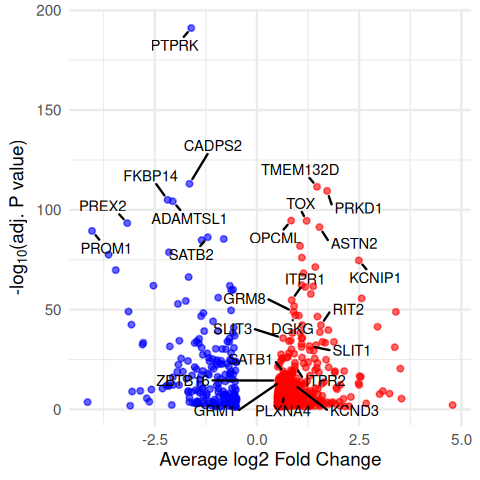

In [ ]:

library(ggplot2)
library(dplyr)
library(ggrepel)

options(repr.plot.width = 4, repr.plot.height = 4)

# p值为0时做特殊处理，方便-log10
deg_3_sub$p_val_adj_plot <- ifelse(deg_3_sub$p_val_adj == 0, 1e-300, deg_3_sub$p_val_adj)

special_genes <- c(

'KCNIP1','ITPR1','KCND3','ITPR1','ITPR2','GRM1','GRM8','DGKG','RIT2','SLIT1','SLIT3','SATB1','ZBTB16','TOX','PLXNA4','SATB2'
)


special_labels <- deg_3_sub %>% 
  filter(gene %in% special_genes)

up_pval_top10 <- deg_3_sub %>%
  filter(avg_log2FC > 0) %>%
  arrange(p_val_adj) %>%
  slice_head(n = 5)

down_pval_top10 <- deg_3_sub %>%
  filter(avg_log2FC < 0) %>%
  arrange(p_val_adj) %>%
  slice_head(n = 7)

# 合并所有需要标注的基因，去重，并加入特定展示的基因
top_labels <- bind_rows(
    # up_logfc_top10, 
    up_pval_top10, 
    # down_logfc_top10, 
    down_pval_top10, 
    special_labels
  ) %>%
  distinct(gene, .keep_all = TRUE)

# 标记红色为上调基因（logFC > 0），蓝色为下调基因
deg_3_sub$color_group <- ifelse(deg_3_sub$avg_log2FC > 0, "Up", "Down")

ggplot(deg_3_sub, aes(x = avg_log2FC, y = -log10(p_val_adj_plot))) +
  geom_point(aes(color = color_group), alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("Up" = "red", "Down" = "blue")) +
  geom_text_repel(
    data = top_labels,
    aes(label = gene),
    color = "black",
    size = 3,
    box.padding = 0.4,
    point.padding = 0.3,
    min.segment.length = 0,
    max.overlaps = Inf
  ) +
  labs(
    x = "Average log2 Fold Change",
    y = expression('-log'[10]*'(adj. P value)')
  ) +
  theme_minimal() +
  theme(legend.position = "none")


In [57]:

library(ggplot2)
library(dplyr)
library(ggrepel)

# 保存为 PDF，宽高4x4
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251223_betz_deg_volcano.pdf", width = 4, height = 4)

# p值为0时做特殊处理，方便-log10
deg_3_sub$p_val_adj_plot <- ifelse(deg_3_sub$p_val_adj == 0, 1e-300, deg_3_sub$p_val_adj)

# 指定需要在火山图上展示的基因
special_genes <- c(
  'KCNIP1','ITPR1','KCND3','ITPR1','ITPR2','GRM1','GRM8','DGKG','RIT2','SLIT1','SLIT3','SATB1','ZBTB16','TOX','PLXNA4','SATB2'
)

special_labels <- deg_3_sub %>% 
  filter(gene %in% special_genes)

# 上调（logFC>0）基因，选择p值前5
up_pval_top10 <- deg_3_sub %>%
  filter(avg_log2FC > 0) %>%
  arrange(p_val_adj) %>%
  slice_head(n = 5)

# 下调（logFC<0）基因，选择p值前7
down_pval_top10 <- deg_3_sub %>%
  filter(avg_log2FC < 0) %>%
  arrange(p_val_adj) %>%
  slice_head(n = 7)

# 合并所有需要标注的基因，去重，并加入特定展示的基因
top_labels <- bind_rows(
    up_pval_top10, 
    down_pval_top10, 
    special_labels
  ) %>%
  distinct(gene, .keep_all = TRUE)

# 标记红色为上调基因（logFC > 0），蓝色为下调基因
deg_3_sub$color_group <- ifelse(deg_3_sub$avg_log2FC > 0, "Up", "Down")

ggplot(deg_3_sub, aes(x = avg_log2FC, y = -log10(p_val_adj_plot))) +
  geom_point(aes(color = color_group), alpha = 0.6, size = 1.2) +
  scale_color_manual(values = c("Up" = "red", "Down" = "blue")) +
  geom_text_repel(
    data = top_labels,
    aes(label = gene),
    color = "black",
    size = 3,
    box.padding = 0.4,
    point.padding = 0.3,
    min.segment.length = 0,
    max.overlaps = Inf
  ) +
  labs(
    x = "Average log2 Fold Change",
    y = expression('-log'[10]*'(adj. P value)')
  ) +
  theme_minimal() +
  theme(legend.position = "none")

dev.off()


agg_record_1839402230 
                    2

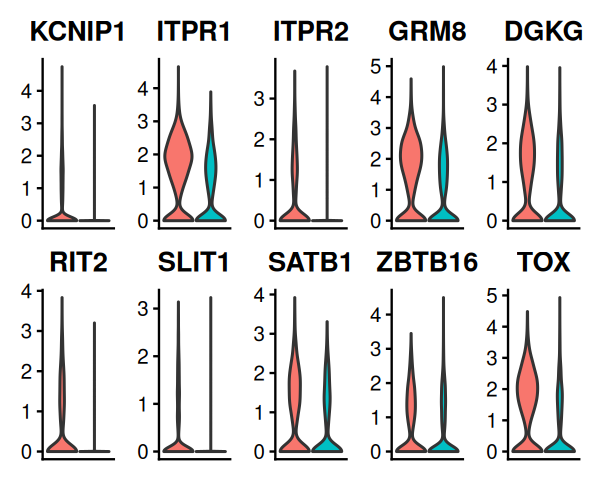

In [ ]:
options(repr.plot.width = 5, repr.plot.height = 4) # 稍微加宽宽度以适应 6 个图

# features = c('KCNIP1','ITPR1','ITPR2','GRM8','DGKG','RIT2','SLIT1','SATB1','ZBTB16','TOX'), 

VlnPlot(sub_rna, 
        features = c('KCNIP1','ITPR1','GRM8','DGKG','RIT2','SLIT1','SLIT3','SATB1','ZBTB16','TOX'), 
        pt.size = 0, 
        ncol = 5) & 
  theme(axis.title.x = element_blank(), # 去除 x 轴标题
        axis.text.x = element_blank(),  # 去除 x 轴刻度标签
        axis.ticks.x = element_blank(),
        axis.title.y = element_blank()
        ) # 去除 x 轴刻度线


In [77]:
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251223_vlnplot_ETclass_splitted_genes-1.pdf", width = 5, height = 4)
options(repr.plot.width = 5, repr.plot.height = 4)

VlnPlot(sub_rna, 
        features = c('KCNIP1','ITPR1','GRM8','DGKG','RIT2','SLIT1','SLIT3','SATB1','ZBTB16','TOX'), 
        pt.size = 0, 
        ncol = 5) & 
  theme(axis.title.x = element_blank(), # 去除 x 轴标题
        axis.text.x = element_blank(),  # 去除 x 轴刻度标签
        axis.ticks.x = element_blank(),
        axis.title.y = element_blank()
        ) # 去除 x 轴刻度线
dev.off()


agg_record_86462374 
                  2

In [73]:
library(ggplot2)

# 1. 提取绘图数据
# features 是你的基因列表
genes <- c('KCNIP1','ITPR1','ITPR2','GRM8','DGKG','RIT2','SLIT1','SATB1','ZBTB16','TOX')

# FetchData 会提取表达量和分组信息
plot_data <- FetchData(sub_rna, vars = c(genes, "ET_class"))

# 2. 将数据从宽表转为长表，方便 ggplot 分面
plot_data_long <- reshape2::melt(plot_data, id.vars = "ET_class", variable.name = "Gene", value.name = "Expression")

# 3. 绘图
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251223_vlnplot_ETclass_splitted_genes.pdf", width = 5, height = 4)
# options(repr.plot.width = 5, repr.plot.height = 4)
ggplot(plot_data_long, aes(x = ET_class, y = Expression, fill = ET_class)) +
  geom_violin(scale = "width", trim = TRUE) +
  # 使用 facet_wrap 分两行，每行 6 个，并强制共用 Y 轴
  facet_wrap(~Gene, ncol = 5, scales = "fixed") + 
  # 在这里统一设置你想要的 Y 轴范围
  scale_y_continuous(limits = c(0, 4)) + 
  theme_classic() +
  theme(
    strip.background = element_blank(),     # 去掉基因名字的背景框
    strip.text = element_text(face = "italic", size = 10), # 基因名斜体
    axis.text.x = element_text(angle = 45, hjust = 1),     # X 轴标签倾斜
    legend.position = "none"                # 如果不需要图例可以关掉
  )  + 
  theme(axis.title.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.y = element_blank())

dev.off()

Warning message:
“Removed 22 rows containing non-finite outside the scale range
(`stat_ydensity()`).”


agg_record_1736473833 
                    2

In [59]:
# 保存为pdf
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251223_vlnplot_ETclass_splitted_genes.pdf", width = 8, height = 4)

VlnPlot(
  sub_rna,
  features = c('KCNIP1','KCND3','ITPR1','ITPR2','GRM1','GRM8','DGKG','RIT2','SLIT3','SATB1','ZBTB16','TOX'),
  group.by = "ET_class",           # 主分组为cluster
  split.by = "ET_class",        # split小提琴为ET_class
  pt.size = 0,
  stack = FALSE,                # 不做堆叠，做两边分开
  fill.by = "split",            # 让左右颜色反映split分组
  ncol = 6
) & 
  theme(
    axis.title.x = element_blank(),
    axis.text.x = element_blank(),
    axis.ticks.x = element_blank(),
    axis.title.y = element_blank()
  )

dev.off()

agg_record_1999281065 
                    2

In [80]:
deg_3$cluster <- ifelse(deg_3$avg_log2FC > 0, "betz", "other L5ET")
deg_3

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene,cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
POSTN,0.000000e+00,-4.9281742,0.075,0.680,0.000000e+00,POSTN,other L5ET
PTPRK,3.532859e-196,-1.6054102,0.561,0.820,8.233681e-192,PTPRK,other L5ET
CADPS2,3.667570e-118,-1.6493130,0.375,0.644,8.547638e-114,CADPS2,other L5ET
TMEM132D,1.133653e-116,1.4685264,0.699,0.355,2.642091e-112,TMEM132D,betz
PRKD1,1.309835e-114,1.7158324,0.603,0.264,3.052700e-110,PRKD1,betz
FKBP14,4.223241e-110,-2.1844540,0.167,0.471,9.842685e-106,FKBP14,other L5ET
ADAMTSL1,2.192882e-109,-2.0584984,0.203,0.517,5.110731e-105,ADAMTSL1,other L5ET
OPCML,1.041243e-99,0.8366375,0.930,0.833,2.426720e-95,OPCML,betz
TOX,1.328066e-99,1.2132266,0.697,0.377,3.095190e-95,TOX,betz


In [81]:
table(deg_3$cluster)


      betz other L5ET 
       383        197 

In [82]:
gene_list_up <- split(deg_3$gene,deg_3$cluster)
gene_list_up

$betz
  [1] "TMEM132D"   "PRKD1"      "OPCML"      "TOX"        "ASTN2"     
  [6] "LARGE1"     "KAZN"       "KCNIP1"     "NETO1"      "MAN2A1"    
 [11] "CADM1"      "ADGRL2"     "KLHL32"     "ITGAV"      "ST8SIA2"   
 [16] "ITPR1"      "LSAMP"      "SEC16B"     "GRM8"       "DGKG"      
 [21] "SOX5"       "SYNPO2"     "SEZ6L"      "RIT2"       "RXFP2"     
 [26] "PRSS12"     "RUNX1T1"    "CRTAC1"     "PLCH1"      "SYN3"      
 [31] "SLIT3"      "SEMA6D"     "NELL1"      "SORCS3"     "ABHD3"     
 [36] "STARD13"    "HS3ST4"     "SLC4A7"     "EPB41L4A"   "SLIT1"     
 [41] "RGS6"       "NRP2"       "PCDH17"     "UBASH3B"    "SNTG1"     
 [46] "SEC24D"     "LNX1"       "AFF3"       "CNTN3"      "HS3ST2"    
 [51] "CACNA1E"    "SLC35F3"    "PLEKHA2"    "NUAK1"      "SYT17"     
 [56] "PSME4"      "CELF4"      "BCL11A"     "PDP1"       "SLC24A2"   
 [61] "NDST3"      "ITPR2"      "RASAL2"     "CBLN4"      "SYNJ2"     
 [66] "UST"        "WFDC2"      "FRMD6"      "ASXL3"      "TECTA"     
 [71] "CNR1"       "MTUS2"      "NEMP2"      "LCP1"       "RASL10A"   
 [76] "PLD5"       "MET"        "PRKAR2B"    "KIAA1456"   "SATB1"     
 [81] "PITPNC1"    "UTRN"       "KCNK1"      "PDE8B"      "TRPC5"     
 [86] "RUNX2"      "PAMR1"      "EPHA5"      "ANKRD28"    "STXBP6"    
 [91] "PRKAG2"     "DDHD1"      "SESN3"      "B3GLCT"     "SSBP3"     
 [96] "EPHA7"      "ABCA9"      "LRRTM3"     "CD46"       "ANKDD1A"   
[101] "FBXO32"     "ZBTB16"     "GRM1"       "SMYD2"      "RBMS3"     
[106] "SLC12A3"    "TPD52L1"    "CALN1"      "CEP112"     "BAZ2B"     
[111] "CDK14"      "ST3GAL1"    "RASGRP2"    "AK5"        "PPP4R4"    
[116] "KIAA1211L"  "PDZRN3"     "STAMBPL1"   "SERPINF1"   "TMEM155"   
[121] "SDK2"       "CAMK4"      "KCND3"      "SV2B"       "DDR2"      
[126] "ANKMY1"     "STUM"       "ACAN"       "NAV3"       "GRIK4"     
[131] "SORBS2"     "KIF26B"     "SYT12"      "FGD4"       "UNC5D"     
[136] "MAMLD1"     "FLT3"       "GSE1"       "HSF4"       "ANXA5"     
[141] "DRD3"       "SRGAP1"     "HAVCR2"     "RELL2"      "PLEKHG1"   
[146] "TIAM1"      "ST6GALNAC5" "TCERG1L"    "KCNS1"      "SGSM1"     
[151] "NDST4"      "TENM4"      "PASK"       "KCNAB2"     "ITPKA"     
[156] "NMT2"       "PALM2"      "SPAG1"      "PLA2R1"     "ADAMTS2"   
[161] "PDE3A"      "EPHB1"      "PALMD"      "GLDC"       "PGRMC1"    
[166] "VASH2"      "FAM189A1"   "GPR158"     "C1QL3"      "ANXA4"     
[171] "OCA2"       "FXYD6"      "ZNF395"     "IGF1R"      "ANKRD33B"  
[176] "GALNT9"     "PLXNA4"     "IQCA1"      "SLC2A9"     "GRAMD2A"   
[181] "PTPRE"      "DOCK11"     "ZNF385D"    "MCF2"       "UCHL3"     
[186] "SPP1"       "DHRS9"      "ABLIM2"     "MAN1A1"     "CACNB2"    
[191] "RBM20"      "GRIK3"      "TCF20"      "JAM2"       "EIF4E3"    
[196] "PIP4K2C"    "LIMS1"      "RHOBTB3"    "GRK4"       "SLC47A1"   
[201] "COL16A1"    "ADAMTS17"   "SEMA3E"     "ABCA5"      "PRIM2"     
[206] "DAPK3"      "COL19A1"    "ADAMTS19"   "SPATA1"     "PAPLN"     
[211] "ACVR1"      "RXFP1"      "LMO2"       "WDR63"      "USP54"     
[216] "GNG2"       "PHKA1"      "TNFRSF21"   "UNC13A"     "KCNC1"     
[221] "CACNA2D2"   "PCP4L1"     "SLC25A40"   "CLGN"       "PDZD7"     
[226] "SLC6A15"    "PLPPR5"     "FNDC4"      "APRT"       "KREMEN2"   
[231] "MSI2"       "RAB30"      "CABP7"      "ADRA1B"     "EFHD2"     
[236] "NNMT"       "RPS6KA2"    "ICK"        "KANK4"      "TESC"      
[241] "CPLX1"      "FGF9"       "EFHC2"      "SPINK5"     "MYH9"      
[246] "SYT2"       "BHMT2"      "SERPINE2"   "ABCA6"      "ECM1"      
[251] "PRKAB2"     "KCNK12"     "FHL2"       "NPTX2"      "CHN2"      
[256] "TECPR1"     "AP5Z1"      "C12orf42"   "HTR7"       "N4BP2"     
[261] "TRPM2"      "CDH22"      "NOS1"       "HCRTR2"     "MAL2"      
[266] "FAT1"       "WNT9A"      "SYT6"       "CAMK1G"     "PXMP2"     
[271] "MYO15A"     "IL34"       "NDP"        "RNF112"     "FAM189A2"  
[276] "FBXO2"      "PLEKHA7"    "PLD1"       "SEPT4"      "PLS1"      
[281] "INPP5J"    

In [ ]:

# gene_list_up = gene_list_up[sapply(gene_list_up, length) > 0]
lapply(names(gene_list_up), function(x){
  enrichr(gene_list_up[[x]], c("GO_Biological_Process_2025"))$GO_Biological_Process_2025 %>%
    mutate(cluster = x)
}) %>% bind_rows() -> GO_df_up1

Welcome to enrichR
Checking connections ... 



Enrichr ... 
Connection is Live!

FlyEnrichr ... 
Connection is Live!

WormEnrichr ... 
Connection is Live!

YeastEnrichr ... 
Connection is Live!

FishEnrichr ... 
Connection is Live!

OxEnrichr ... 
Connection is Live!



Uploading data to Enrichr... Done.
  Querying GO_Biological_Process_2025... Done.
Parsing results... Done.
Uploading data to Enrichr... Done.
  Querying GO_Biological_Process_2025... Done.
Parsing results... Done.


In [102]:
go_sub1 = subset(GO_df_up1, cluster == "betz")
go_sub1= subset(go_sub1, Term != 'T Cell Mediated Immunity (GO:0002456)')
go_sub1 %>% head()

,Term,Overlap,P.value,Adjusted.P.value,Old.P.value,Old.Adjusted.P.value,Odds.Ratio,Combined.Score,Genes,cluster
,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
1,Anterograde Trans-Synaptic Signaling (GO:0098916),16/189,7.779087e-07,0.001414238,0,0,4.899970,68.92620,UNC13C;KCNIP1;KCND3;GRIK4;CACNA1E;CPLX1;GRM1;SYT6;GRM3;CACNB2;HTR7;RIT2;RPS6KA2;PXMP2;NPTX2;SNCB,betz
2,Chemical Synaptic Transmission (GO:0007268),18/260,2.987083e-06,0.002715259,0,0,3.948262,50.22668,UNC13C;UNC13A;KCNIP1;KCND3;GRIK3;GRIK4;CACNA1E;CPLX1;GRM1;SYT6;GRM3;CACNB2;HTR7;RIT2;RPS6KA2;PXMP2;NPTX2;SNCB,betz
3,Neuron Projection Guidance (GO:0097485),12/132,9.070962e-06,0.005497003,0,0,5.255256,61.01579,EPHA5;CYFIP1;EPHA7;NRP2;SEMA3D;SEMA6D;SEMA3E;SLIT3;UNC5D;EMB;EPHB1;PLXNA4,betz
5,Axon Guidance (GO:0007411),12/152,3.753922e-05,0.013649260,0,0,4.499884,45.85438,EPHA5;CYFIP1;EPHA7;NRP2;SEMA3D;SEMA6D;SEMA3E;SLIT3;UNC5D;EMB;EPHB1;PLXNA4,betz
6,Negative Chemotaxis (GO:0050919),5/25,9.719231e-05,0.029449270,0,0,12.960979,119.74414,EPHA7;SEMA3D;SEMA3E;ITGAV;SLIT3,betz
7,G Protein-Coupled Glutamate Receptor Signaling Pathway (GO:0007216),4/14,1.138212e-04,0.029560985,0,0,20.693404,187.91436,GRM3;GRM8;GRIK3;GRM1,betz


In [90]:
go_sub2 = subset(GO_df_up1, cluster == "other L5ET")
go_sub2 %>% head()

,Term,Overlap,P.value,Adjusted.P.value,Old.P.value,Old.Adjusted.P.value,Odds.Ratio,Combined.Score,Genes,cluster
,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
1819,Positive Regulation of Cell Junction Assembly (GO:1901890),6/65,4.311866e-05,0.04648191,0,0,10.512379,105.66575,CNTNAP2;NRP1;NLGN1;CLSTN2;IL1RAP;DSG3,other L5ET
1820,Positive Regulation of Plasma Membrane Bounded Cell Projection Assembly (GO:0120034),6/90,2.651769e-04,0.10798470,0,0,7.374346,60.72857,EPS8;NRP1;NLGN1;PLCE1;FNBP1L;TAPT1,other L5ET
1821,Cell-Cell Adhesion via Plasma-Membrane Adhesion Molecules (GO:0098742),8/171,3.005140e-04,0.10798470,0,0,5.100140,41.36221,SDK1;NLGN1;CDH10;CDH11;HMCN1;CDH18;ROBO1;CBLN1,other L5ET
1822,Cell Junction Assembly (GO:0034329),6/101,4.936651e-04,0.11359199,0,0,6.516837,49.61693,SDK1;NLGN1;CDH10;CDH11;PLXNC1;CDH18,other L5ET
1823,Synapse Organization (GO:0050808),7/144,5.701936e-04,0.11359199,0,0,5.288590,39.50331,SDK1;PPFIBP1;NLGN1;CDH10;PLXNC1;CBLN2;CBLN1,other L5ET
1824,Calcium-Dependent Cell-Cell Adhesion via Plasma Membrane Cell Adhesion Molecules (GO:0016339),4/40,6.322374e-04,0.11359199,0,0,11.379965,83.82762,NLGN1;CDH10;CDH11;CDH18,other L5ET


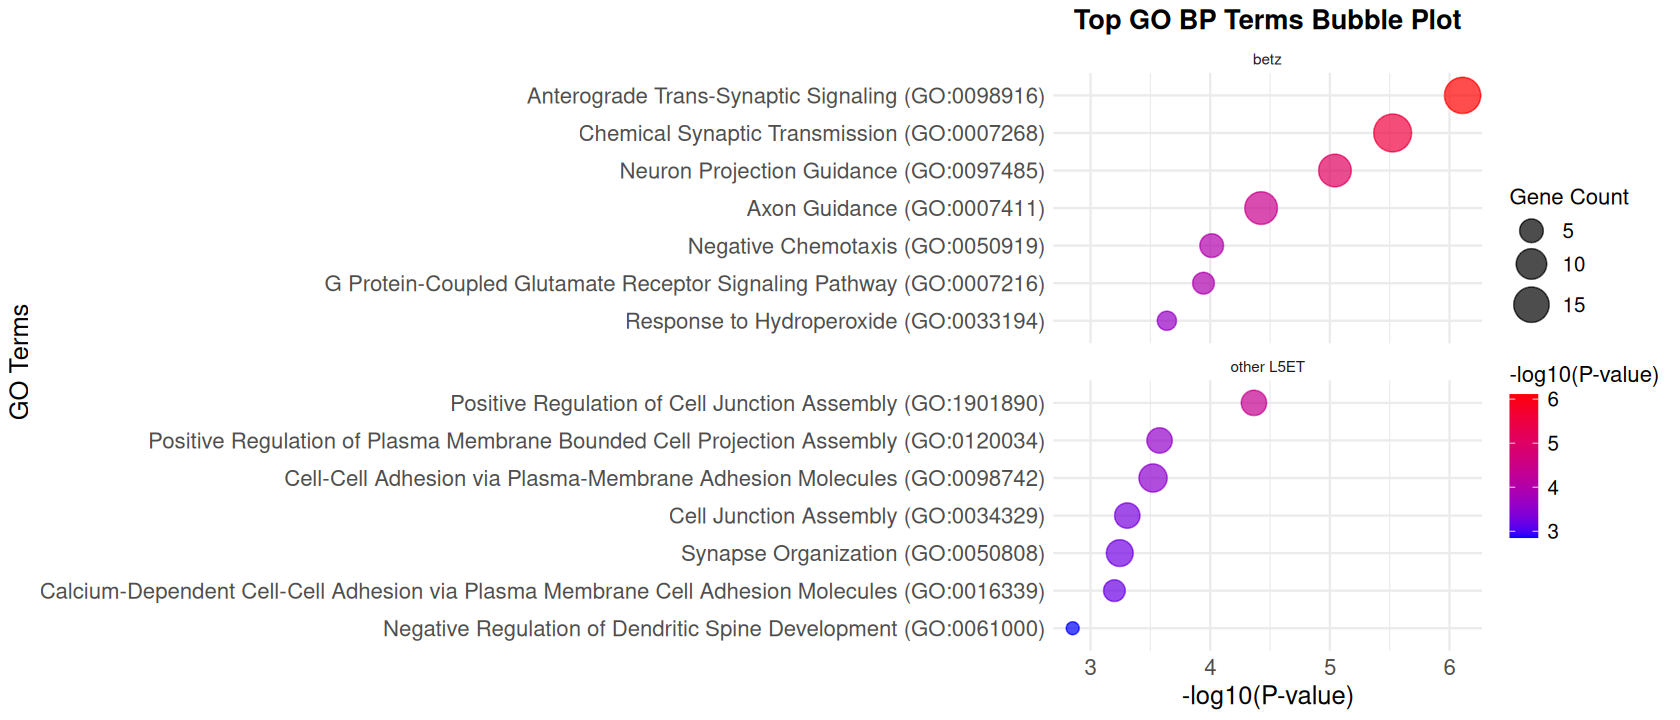

In [105]:
# 气泡图展示两个表中前面的结果，纵向排列

library(ggplot2)
options(repr.plot.width=14, repr.plot.height=6) # 纵向排列，设置较高plot高度

# 选择展示前N项
top_n_show <- 7
top_go1 <- head(go_sub1, top_n_show)
top_go2 <- head(go_sub2, top_n_show)

# 重新加标签
top_go1$cluster <- "betz"
top_go2$cluster <- "other L5ET"
top_go <- rbind(top_go1, top_go2)
top_go$GeneCount <- as.numeric(sub("/.*", "", top_go$Overlap))

# 纵向排列两个集群，使用facet_wrap的ncol=1实现竖排
ggplot(top_go, aes(x = -log10(P.value), 
                   y = reorder(Term, -log10(P.value)), 
                   size = GeneCount, 
                   color = -log10(P.value))) +
  geom_point(alpha = 0.7) +
  scale_size_continuous(name = "Gene Count", range = c(3, 10)) +
  scale_color_gradient(low = "blue", high = "red", name = "-log10(P-value)") +
  labs(title = "Top GO BP Terms Bubble Plot",
       x = "-log10(P-value)",
       y = "GO Terms") +
  theme_minimal() +
  theme(axis.text.y = element_text(size = 13),
        axis.text.x = element_text(size = 13),
        axis.title.x = element_text(size = 15),
        axis.title.y = element_text(size = 15),
        legend.title = element_text(size = 13),
        legend.text = element_text(size = 12),
        plot.title = element_text(hjust = 0.5, size = 16, face = "bold")) +
  facet_wrap(~cluster, scales = "free_y", ncol = 1) # ncol=1实现纵向排列



In [106]:
# 气泡图展示两个表中前面的结果，纵向排列，并保存为 PDF

library(ggplot2)

# 选择展示前N项
top_n_show <- 7
top_go1 <- head(go_sub1, top_n_show)
top_go2 <- head(go_sub2, top_n_show)

# 重新加标签
top_go1$cluster <- "betz"
top_go2$cluster <- "other L5ET"
top_go <- rbind(top_go1, top_go2)
top_go$GeneCount <- as.numeric(sub("/.*", "", top_go$Overlap))

# 保存到PDF
pdf("/mnt/90-connectome/Personal/CQW/motor_snRNA_new/article/fig5/new_betz/co_betz_snRNA/20251224_top_go_bubble_plot.pdf", width = 14, height = 6)

ggplot(top_go, aes(x = -log10(P.value), 
                   y = reorder(Term, -log10(P.value)), 
                   size = GeneCount, 
                   color = -log10(P.value))) +
  geom_point(alpha = 0.7) +
  scale_size_continuous(name = "Gene Count", range = c(3, 10)) +
  scale_color_gradient(low = "blue", high = "red", name = "-log10(P-value)") +
  labs(title = "Top GO BP Terms Bubble Plot",
       x = "-log10(P-value)",
       y = "GO Terms") +
  theme_minimal() +
  theme(axis.text.y = element_text(size = 13),
        axis.text.x = element_text(size = 13),
        axis.title.x = element_text(size = 15),
        axis.title.y = element_text(size = 15),
        legend.title = element_text(size = 13),
        legend.text = element_text(size = 12),
        plot.title = element_text(hjust = 0.5, size = 16, face = "bold")) +
  facet_wrap(~cluster, scales = "free_y", ncol = 1) # ncol=1实现纵向排列

dev.off()


agg_record_908823106 
                   2